Attempting to download data...
  Data shape: (1256, 5), Columns: [('Close', 'AAPL'), ('High', 'AAPL'), ('Low', 'AAPL'), ('Open', 'AAPL'), ('Volume', 'AAPL')]
  Downloaded 1256 prices for 5 years
✔ Data recovered using 5 years

Price data: min=113.44, max=286.19, mean=180.15
Prices: 1256
Returns: 1255

alpha = 1704.161922
Gaussian-equivalent sigma = 0.017129
Actual sigma = 0.017422


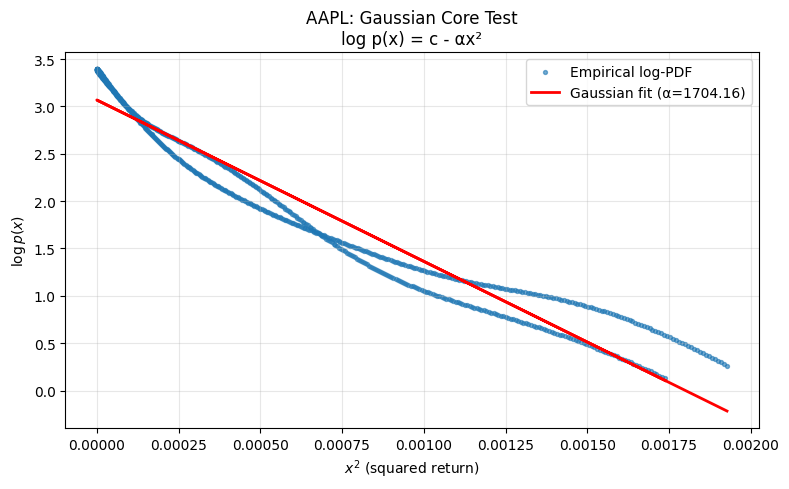

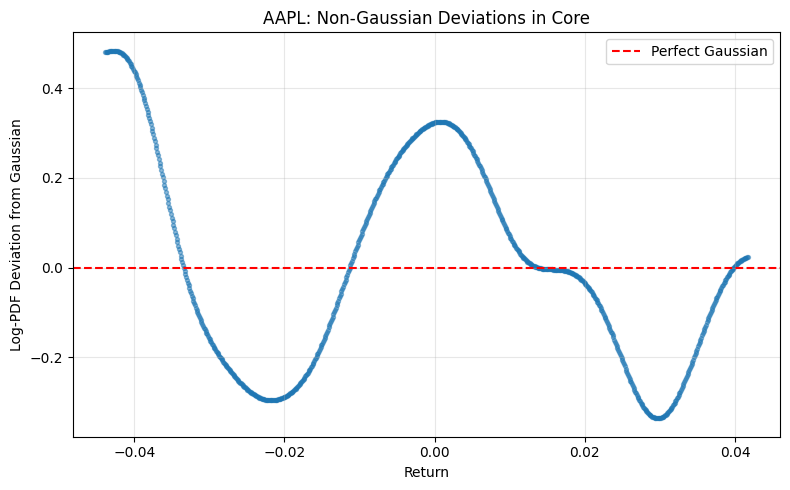

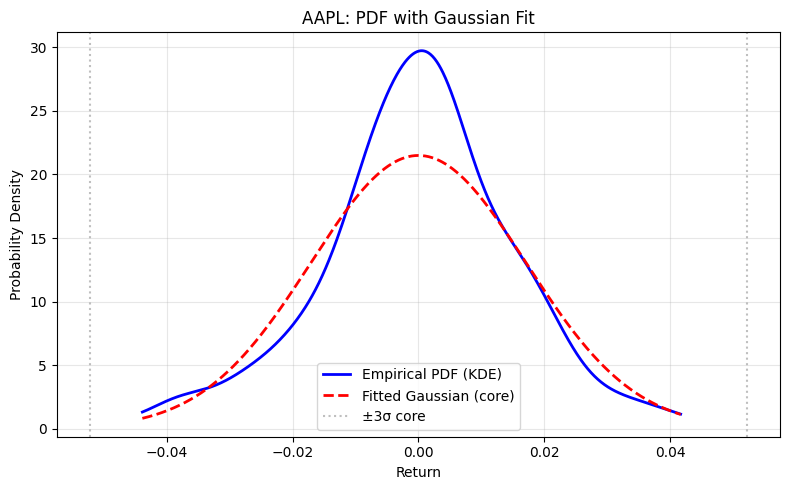

Attempting to download data...
  Data shape: (1256, 5), Columns: [('Close', 'MSFT'), ('High', 'MSFT'), ('Low', 'MSFT'), ('Open', 'MSFT'), ('Volume', 'MSFT')]
  Downloaded 1256 prices for 5 years
✔ Data recovered using 5 years

Price data: min=204.05, max=541.06, mean=343.90
Prices: 1256
Returns: 1255

alpha = 1962.281012
Gaussian-equivalent sigma = 0.015963
Actual sigma = 0.016139


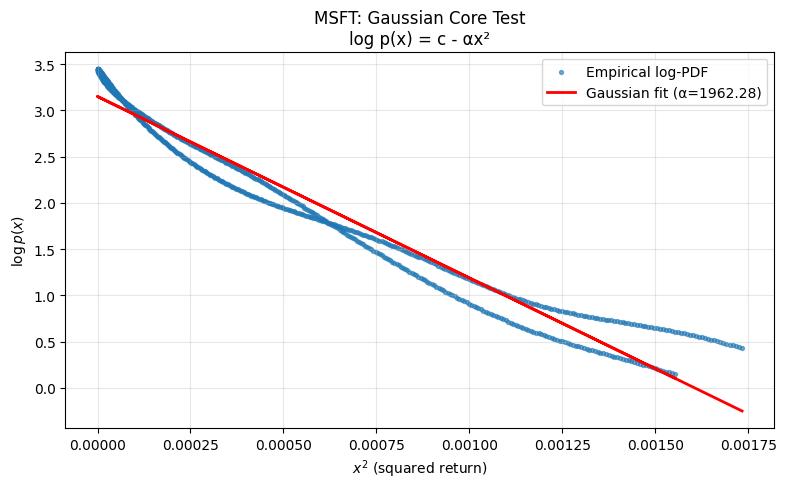

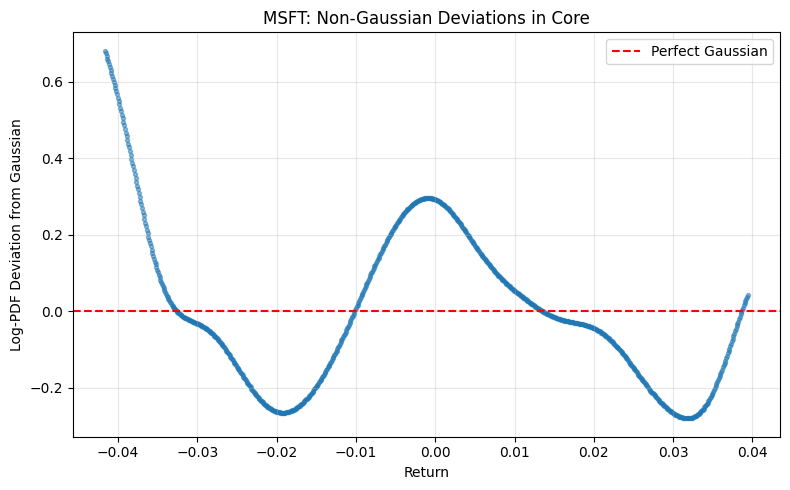

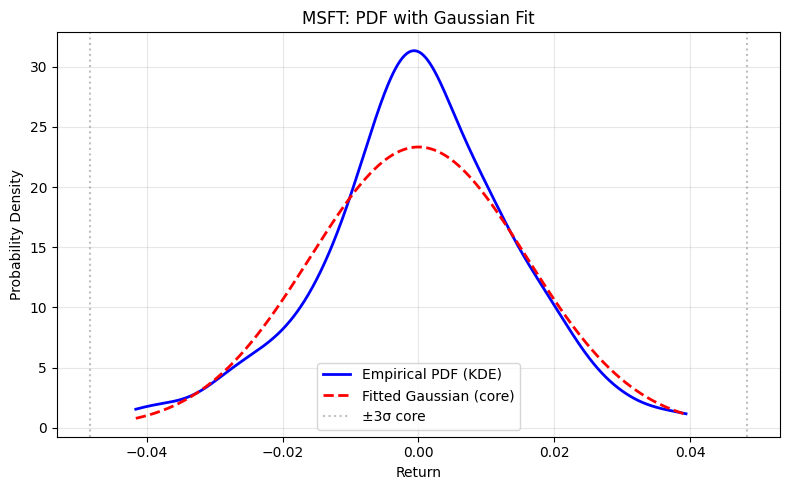

Attempting to download data...
  Data shape: (1258, 5), Columns: [('Close', 'GC=F'), ('High', 'GC=F'), ('Low', 'GC=F'), ('Open', 'GC=F'), ('Volume', 'GC=F')]
  Downloaded 1258 prices for 5 years
✔ Data recovered using 5 years

Price data: min=1623.30, max=4586.80, mean=2290.42
Prices: 1258
Returns: 1257

alpha = 4644.324263
Gaussian-equivalent sigma = 0.010376
Actual sigma = 0.010045


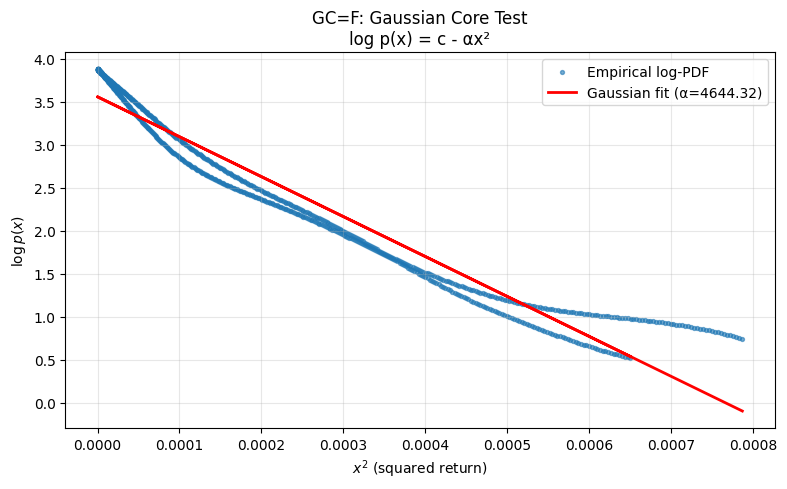

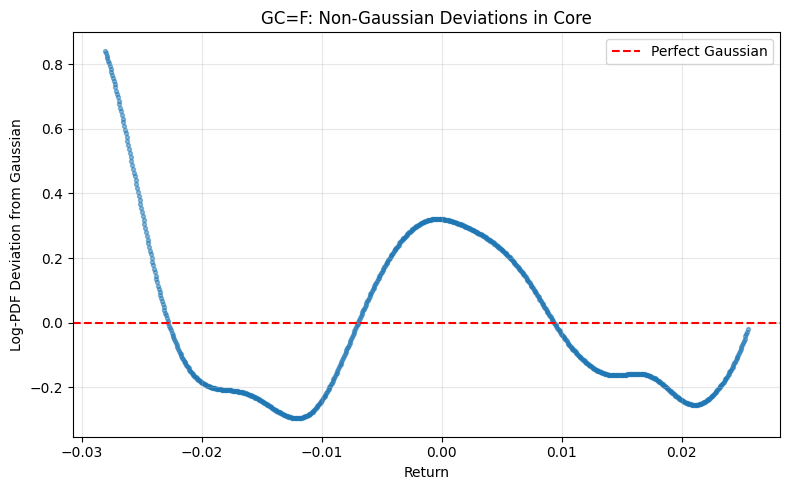

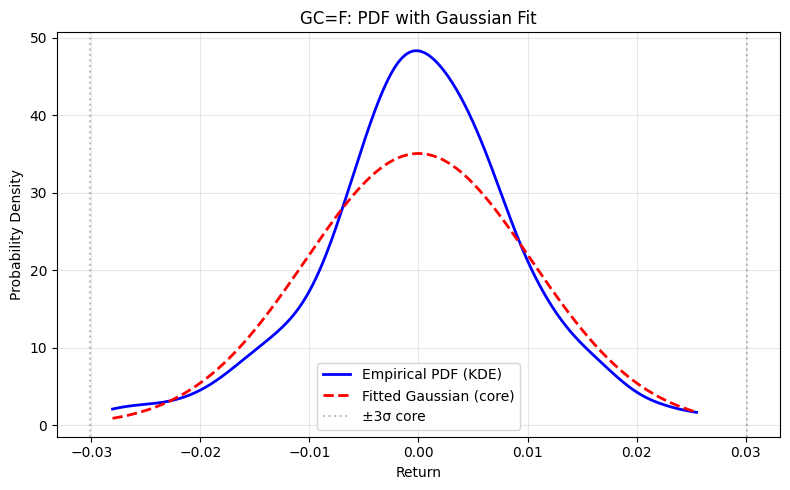

In [18]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# -----------------------------
# Parameters
# -----------------------------
tickers = ["AAPL","MSFT","GC=F"]
start_years = [5, 10, 20]  # progressively widen window
min_returns = 200
prices = None

# -----------------------------
# Robust data download loop
# -----------------------------
for ticker in tickers:
        print("Attempting to download data...")
        for yrs in start_years:
            try:
                data = yf.download(
                    ticker,
                    period=f"{yrs}y",
                    interval="1d",
                    auto_adjust=True,
                    progress=False
                )
                if data.empty:
                    print(f"  No data for {yrs} years, trying next...")
                    continue
                
                # Handle both single and multi-column formats
                print(f"  Data shape: {data.shape}, Columns: {data.columns.tolist()}")
                
                # Check if columns are MultiIndex (tuple format)
                if isinstance(data.columns[0], tuple):
                    # Multi-index columns like ('Close', 'AAPL')
                    close_prices = data[('Close', ticker)].dropna().values
                else:
                    # Simple columns like 'Close'
                    close_prices = data["Close"].dropna().values
                
                print(f"  Downloaded {len(close_prices)} prices for {yrs} years")
                
                if len(close_prices) > min_returns:
                    prices = close_prices
                    print(f"✔ Data recovered using {yrs} years")
                    break
            except Exception as e:
                print(f"  Error with {yrs} years: {e}")
                continue

        if prices is None or len(prices) <= min_returns:
            raise RuntimeError(f"Could not download sufficient data for {ticker}. Try a different ticker or check your internet connection.")

        print(f"\nPrice data: min={np.min(prices):.2f}, max={np.max(prices):.2f}, mean={np.mean(prices):.2f}")

        # -----------------------------
        # Log returns
        # -----------------------------
        # Check for valid prices first
        if np.any(prices <= 0):
            print(f"Warning: Found {np.sum(prices <= 0)} non-positive prices. Removing them.")
            prices = prices[prices > 0]

        if len(prices) < 2:
            raise RuntimeError(f"Not enough valid prices after filtering: {len(prices)}")

        r = np.diff(np.log(prices))
        r = r[np.isfinite(r)]

        if len(r) < 50:
            raise RuntimeError(f"Insufficient returns data: only {len(r)} valid returns. Need at least 50.")

        r -= np.mean(r)

        print(f"Prices: {len(prices)}")
        print(f"Returns: {len(r)}")

        # -----------------------------
        # KDE PDF (SAFE)
        # -----------------------------
        kde = gaussian_kde(r)
        x = np.linspace(
            np.percentile(r, 1),
            np.percentile(r, 99),
            800
        )
        p = kde(x)

        # -----------------------------
        # Gaussian core (|x| < 3σ)
        # -----------------------------
        sigma = np.std(r)
        core = np.abs(x) < 3 * sigma
        x_core = x[core]
        p_core = p[core]

        # Add safety check for log
        p_core = np.maximum(p_core, 1e-10)  # Prevent log(0)

        # -----------------------------
        # Inverse parabola fit
        # log p(x) = c - alpha x^2
        # -----------------------------
        y = np.log(p_core)
        z = x_core**2
        coeff = np.polyfit(z, y, 1)
        alpha = -coeff[0]
        c = coeff[1]

        print(f"\nalpha = {alpha:.6f}")
        print(f"Gaussian-equivalent sigma = {np.sqrt(1/(2*alpha)):.6f}")
        print(f"Actual sigma = {sigma:.6f}")

        # -----------------------------
        # Diagnostics
        # -----------------------------
        y_fit = c - alpha * z
        deviation = y - y_fit

        # -----------------------------
        # Plot: Inverse Parabola Test
        # -----------------------------
        plt.figure(figsize=(8, 5))
        plt.scatter(z, y, s=8, alpha=0.6, label="Empirical log-PDF")
        plt.plot(z, y_fit, 'r', lw=2, label=f"Gaussian fit (α={alpha:.2f})")
        plt.xlabel(r"$x^2$ (squared return)")
        plt.ylabel(r"$\log p(x)$")
        plt.title(f"{ticker}: Gaussian Core Test\nlog p(x) = c - αx²")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # -----------------------------
        # Plot: Deviation from Gaussian
        # -----------------------------
        plt.figure(figsize=(8, 5))
        plt.scatter(x_core, deviation, s=8, alpha=0.5)
        plt.axhline(0, color='r', linestyle='--', label='Perfect Gaussian')
        plt.xlabel("Return")
        plt.ylabel("Log-PDF Deviation from Gaussian")
        plt.title(f"{ticker}: Non-Gaussian Deviations in Core")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # -----------------------------
        # Plot: Full PDF with Gaussian overlay
        # -----------------------------
        plt.figure(figsize=(8, 5))
        plt.plot(x, p, 'b-', lw=2, label='Empirical PDF (KDE)')
        # Fitted Gaussian from core
        p_gaussian = np.exp(c - alpha * x**2)
        plt.plot(x, p_gaussian, 'r--', lw=2, label='Fitted Gaussian (core)')
        plt.axvline(-3*sigma, color='gray', linestyle=':', alpha=0.5, label='±3σ core')
        plt.axvline(3*sigma, color='gray', linestyle=':', alpha=0.5)
        plt.xlabel("Return")
        plt.ylabel("Probability Density")
        plt.title(f"{ticker}: PDF with Gaussian Fit")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(z, y, s=12, label="Empirical log-PDF")
plt.plot(z, y_fit, 'r', lw=2, label="Gaussian inverse parabola")
plt.xlabel(r"$x^2$")
plt.ylabel(r"$\log p(x)$")
plt.title(f"{ticker}: Gaussian Diagnostic")
plt.legend()
plt.grid(True)
plt.show()


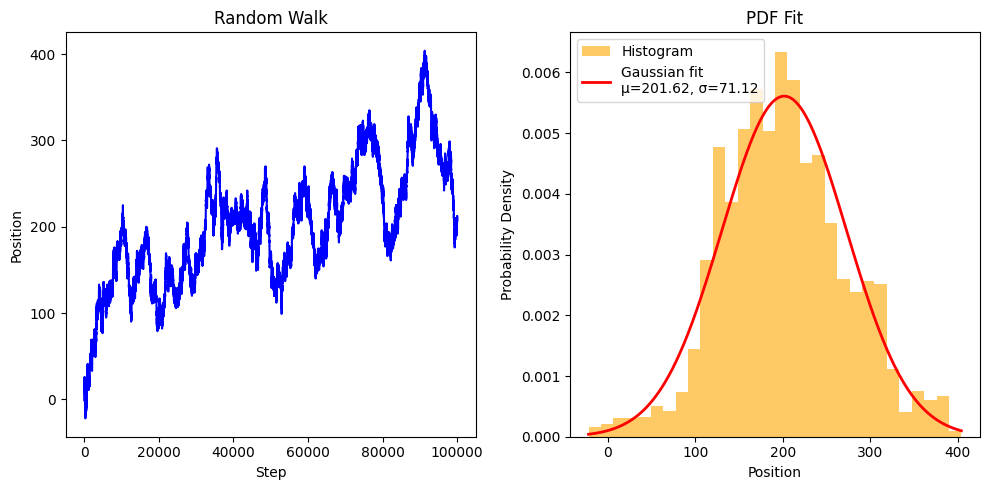

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# -----------------------------
# Parameters
# -----------------------------
n_steps = 100000  # number of steps in the random walk
p = 0.5         # probability of "heads" (step up)

# -----------------------------
# Simulate random walk
# -----------------------------
# 1 for heads, -1 for tails
steps = np.where(np.random.rand(n_steps) < p, 1, -1)
random_walk = np.cumsum(steps)  # cumulative sum gives the walk

# -----------------------------
# Fit Gaussian PDF
# -----------------------------
mu, sigma = np.mean(random_walk), np.std(random_walk)  # mean and std
x = np.linspace(random_walk.min(), random_walk.max(), 1000)
pdf = norm.pdf(x, mu, sigma)

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(10,5))

# Random walk
plt.subplot(1,2,1)
plt.plot(random_walk, color='blue')
plt.title("Random Walk")
plt.xlabel("Step")
plt.ylabel("Position")

# Histogram + Gaussian fit
plt.subplot(1,2,2)
plt.hist(random_walk, bins=30, density=True, alpha=0.6, color='orange', label='Histogram')
plt.plot(x, pdf, 'r-', lw=2, label=f'Gaussian fit\nμ={mu:.2f}, σ={sigma:.2f}')
plt.title("PDF Fit")
plt.xlabel("Position")
plt.ylabel("Probability Density")
plt.legend()


plt.tight_layout()
plt.show()


Analyzing stocks...

Processing AAPL...
  ✓ H(q) std: 0.0549, range: 0.1817
  🟨 WEAKLY MULTIFRACTAL

Processing MSFT...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25444\444767087.py:97: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2015-01-01", end="2025-01-01", progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25444\444767087.py:97: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2015-01-01", end="2025-01-01", progress=False)


  ✓ H(q) std: 0.0754, range: 0.2561
  🟥 MULTIFRACTAL

Processing GOOGL...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25444\444767087.py:97: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2015-01-01", end="2025-01-01", progress=False)


  ✓ H(q) std: 0.0561, range: 0.1836
  🟨 WEAKLY MULTIFRACTAL

Processing AMZN...


...

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25444\444767087.py:97: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2015-01-01", end="2025-01-01", progress=False)


  ✓ H(q) std: 0.1048, range: 0.3350
  🟥 MULTIFRACTAL

Processing BTC-USD...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25444\444767087.py:97: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start="2015-01-01", end="2025-01-01", progress=False)


  ✓ H(q) std: 0.0815, range: 0.2631
  🟥 MULTIFRACTAL


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_25444\444767087.py:190: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\VEDANT\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128997 (\N{LARGE RED SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


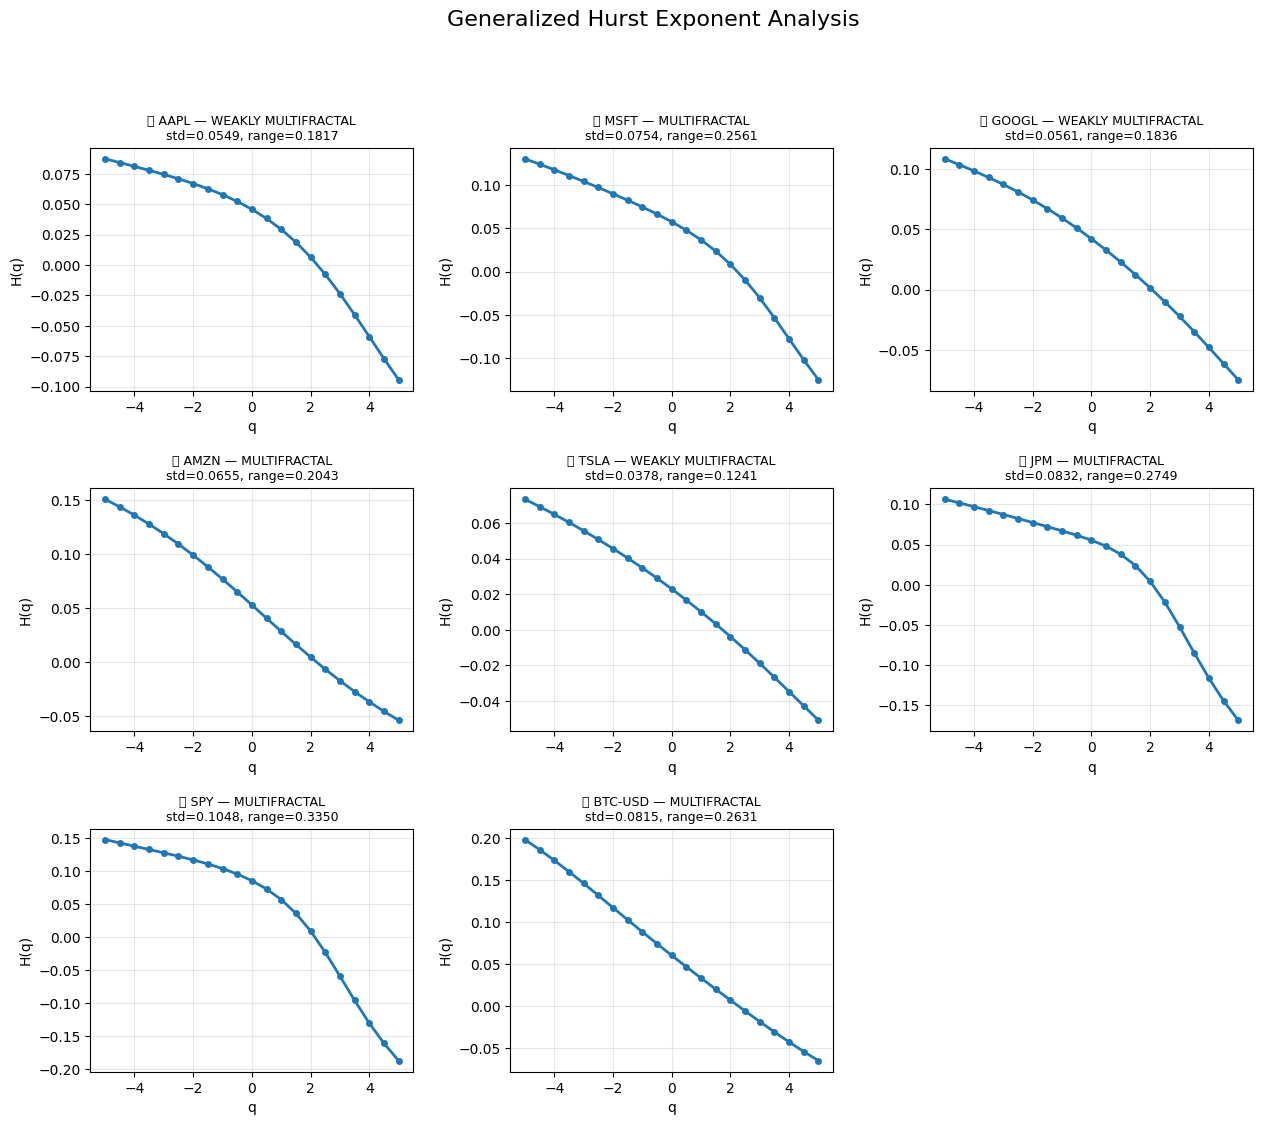


SUMMARY TABLE
Ticker     Type     Std        Range      Classification           
------------------------------------------------------------
SPY        🟥        0.1048     0.3350     MULTIFRACTAL             
JPM        🟥        0.0832     0.2749     MULTIFRACTAL             
BTC-USD    🟥        0.0815     0.2631     MULTIFRACTAL             
MSFT       🟥        0.0754     0.2561     MULTIFRACTAL             
AMZN       🟥        0.0655     0.2043     MULTIFRACTAL             
GOOGL      🟨        0.0561     0.1836     WEAKLY MULTIFRACTAL      
AAPL       🟨        0.0549     0.1817     WEAKLY MULTIFRACTAL      
TSLA       🟨        0.0378     0.1241     WEAKLY MULTIFRACTAL      


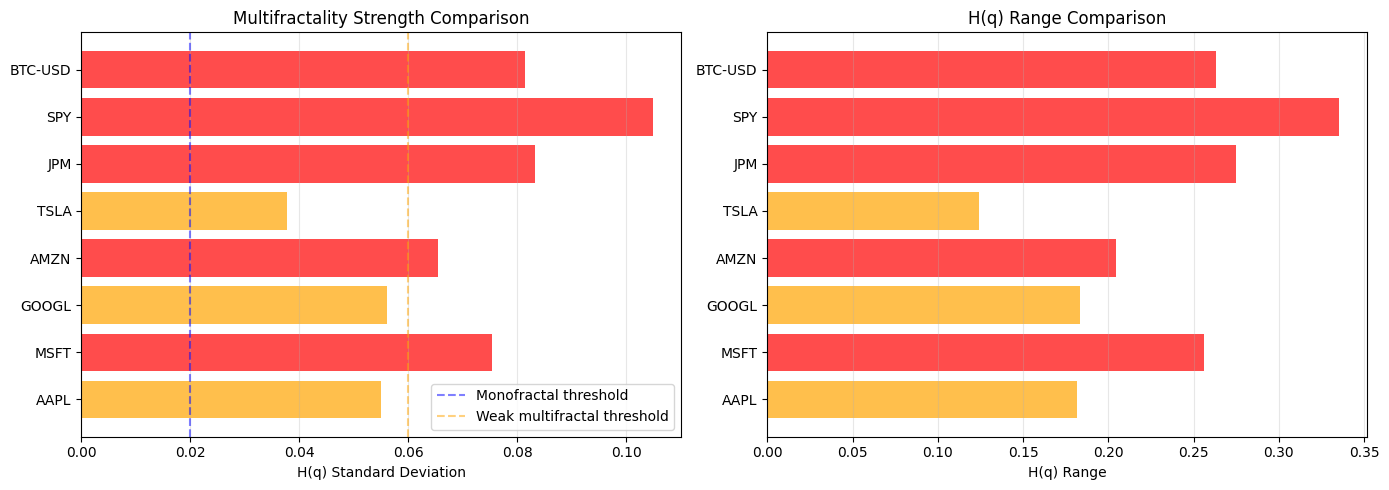


INTERPRETATION
🟦 MONOFRACTAL: Single scaling behavior, similar to random walk
🟨 WEAKLY MULTIFRACTAL: Some complexity, often from fat-tailed distributions
🟥 MULTIFRACTAL: Strong heterogeneity, complex market dynamics


In [8]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# -----------------------------
# Stock list
# -----------------------------
tickers = ["AAPL", "MSFT", "GOOGL", "AMZN", "TSLA", "JPM", "SPY", "BTC-USD"]

# -----------------------------
# Generalized Hurst Exponent Function
# -----------------------------
def generalized_hurst(x, q_vals, scales):
    # Ensure x is 1D
    x = np.asarray(x).flatten()
    
    if len(x) == 0:
        raise ValueError("Input array is empty")
    
    if x.ndim != 1:
        raise ValueError(f"Input must be 1D array, got shape {x.shape}")

    Hq = []

    for q in q_vals:
        Fq = []
        scales_used = []

        for s in scales:
            n = len(x) // s
            if n < 5:
                continue

            cut = n * s
            
            if cut > len(x) or cut == 0:
                continue
            
            x_segment = x[:cut]
            
            if len(x_segment) != cut:
                continue
                
            segments = x_segment.reshape(n, s)

            rms = np.sqrt(np.mean(segments**2, axis=1))
            rms = rms[rms > 0]

            if len(rms) == 0:
                continue

            if abs(q) < 1e-10:
                Fq.append(np.exp(0.5 * np.mean(np.log(rms**2 + 1e-10))))
            else:
                Fq.append((np.mean(rms**q))**(1/q))

            scales_used.append(s)

        if len(Fq) < 5:
            Hq.append(np.nan)
            continue

        Fq = np.array(Fq)
        scales_used = np.array(scales_used)

        try:
            slope, _ = np.polyfit(np.log(scales_used), np.log(Fq + 1e-10), 1)
            Hq.append(slope)
        except:
            Hq.append(np.nan)

    return np.array(Hq)

# -----------------------------
# Parameters
# -----------------------------
q_vals = np.linspace(-5, 5, 21)
scales = np.unique(np.logspace(1.5, 3.5, 25).astype(int))

# -----------------------------
# Storage for results
# -----------------------------
results = {}

# -----------------------------
# Analyze each stock
# -----------------------------
print("Analyzing stocks...")
print("=" * 60)

for ticker in tickers:
    print(f"\nProcessing {ticker}...")
    
    try:
        # Download data
        data = yf.download(ticker, start="2015-01-01", end="2025-01-01", progress=False)
        
        if data.empty:
            print(f"  ❌ No data for {ticker}")
            continue
        
        prices = data["Close"].dropna().values
        prices = np.asarray(prices).flatten()
        
        if len(prices) < 100:
            print(f"  ❌ Insufficient data for {ticker}")
            continue
        
        # Calculate log returns
        r = np.diff(np.log(prices))
        r -= np.mean(r)
        r = np.asarray(r).flatten()
        
        # Filter scales
        valid_scales = scales[scales <= len(r) // 5]
        
        if len(valid_scales) == 0:
            print(f"  ❌ No valid scales for {ticker}")
            continue
        
        # Compute H(q)
        Hq = generalized_hurst(r, q_vals, valid_scales)
        
        # Calculate statistics
        Hq_valid = Hq[~np.isnan(Hq)]
        
        if len(Hq_valid) == 0:
            print(f"  ❌ No valid H(q) values for {ticker}")
            continue
        
        Hq_std = np.std(Hq_valid)
        Hq_range = np.max(Hq_valid) - np.min(Hq_valid)
        
        # Classify
        if Hq_std < 0.02:
            classification = "MONOFRACTAL"
            emoji = "🟦"
        elif 0.02 <= Hq_std < 0.06:
            classification = "WEAKLY MULTIFRACTAL"
            emoji = "🟨"
        else:
            classification = "MULTIFRACTAL"
            emoji = "🟥"
        
        # Store results
        results[ticker] = {
            'Hq': Hq,
            'Hq_std': Hq_std,
            'Hq_range': Hq_range,
            'classification': classification,
            'emoji': emoji,
            'data_points': len(prices)
        }
        
        print(f"  ✓ H(q) std: {Hq_std:.4f}, range: {Hq_range:.4f}")
        print(f"  {emoji} {classification}")
        
    except Exception as e:
        print(f"  ❌ Error processing {ticker}: {str(e)}")

# -----------------------------
# Create comprehensive visualization
# -----------------------------
if len(results) > 0:
    n_stocks = len(results)
    
    # Calculate grid dimensions
    n_cols = 3
    n_rows = (n_stocks + n_cols - 1) // n_cols
    
    fig = plt.figure(figsize=(15, 4 * n_rows))
    gs = GridSpec(n_rows, n_cols, figure=fig, hspace=0.4, wspace=0.3)
    
    for idx, (ticker, data) in enumerate(results.items()):
        row = idx // n_cols
        col = idx % n_cols
        
        ax = fig.add_subplot(gs[row, col])
        
        ax.plot(q_vals, data['Hq'], 'o-', lw=2, markersize=4)
        ax.set_xlabel('q', fontsize=10)
        ax.set_ylabel('H(q)', fontsize=10)
        ax.set_title(f"{data['emoji']} {ticker} — {data['classification']}\n"
                    f"std={data['Hq_std']:.4f}, range={data['Hq_range']:.4f}",
                    fontsize=9)
        ax.grid(True, alpha=0.3)
    
    plt.suptitle('Generalized Hurst Exponent Analysis', fontsize=16, y=0.995)
    plt.tight_layout()
    plt.show()
    
    # -----------------------------
    # Summary table
    # -----------------------------
    print("\n" + "=" * 60)
    print("SUMMARY TABLE")
    print("=" * 60)
    print(f"{'Ticker':<10} {'Type':<8} {'Std':<10} {'Range':<10} {'Classification':<25}")
    print("-" * 60)
    
    # Sort by std (most multifractal first)
    sorted_results = sorted(results.items(), key=lambda x: x[1]['Hq_std'], reverse=True)
    
    for ticker, data in sorted_results:
        print(f"{ticker:<10} {data['emoji']:<8} {data['Hq_std']:<10.4f} "
              f"{data['Hq_range']:<10.4f} {data['classification']:<25}")
    
    # -----------------------------
    # Comparison bar chart
    # -----------------------------
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    tickers_list = list(results.keys())
    stds = [results[t]['Hq_std'] for t in tickers_list]
    ranges = [results[t]['Hq_range'] for t in tickers_list]
    colors = [results[t]['emoji'] for t in tickers_list]
    
    # Map emojis to colors
    color_map = {'🟦': 'blue', '🟨': 'orange', '🟥': 'red'}
    bar_colors = [color_map[c] for c in colors]
    
    # Standard deviation comparison
    ax1.barh(tickers_list, stds, color=bar_colors, alpha=0.7)
    ax1.axvline(x=0.02, color='blue', linestyle='--', alpha=0.5, label='Monofractal threshold')
    ax1.axvline(x=0.06, color='orange', linestyle='--', alpha=0.5, label='Weak multifractal threshold')
    ax1.set_xlabel('H(q) Standard Deviation')
    ax1.set_title('Multifractality Strength Comparison')
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis='x')
    
    # Range comparison
    ax2.barh(tickers_list, ranges, color=bar_colors, alpha=0.7)
    ax2.set_xlabel('H(q) Range')
    ax2.set_title('H(q) Range Comparison')
    ax2.grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.show()
    
    print("\n" + "=" * 60)
    print("INTERPRETATION")
    print("=" * 60)
    print("🟦 MONOFRACTAL: Single scaling behavior, similar to random walk")
    print("🟨 WEAKLY MULTIFRACTAL: Some complexity, often from fat-tailed distributions")
    print("🟥 MULTIFRACTAL: Strong heterogeneity, complex market dynamics")
    print("=" * 60)
    
else:
    print("\n❌ No stocks were successfully analyzed")